# Multiple Object Video Detection — HW2

**Task:** object detection on video frames. Evaluation metric: mAP (COCO-style).

**Structure**:
1. Setup
2. EDA
3. Two-stage anchor-based (Faster R-CNN)
4. One-stage anchor-based (RetinaNet)
5. One-stage anchor-free
6. Query-based
7. Your Pipeline
8. Final model, prediction on test, submission file

## 1. Setup


In [ ]:
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("kaggle").strip()

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
!kaggle competitions download -c multiple-object-video-detection-hw-2-ucu-ai-2026

os.makedirs("data", exist_ok=True)
!unzip -q -o multiple-object-video-detection-hw-2-ucu-ai-2026.zip -d data/
print("Files:", os.listdir("data"))

100% 9.88G/9.88G [02:09<00:00, 82.0MB/s]

Files: ['val', 'train', 'test', 'test_images.csv']


In [ ]:
import json
import pickle
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

plt.style.use("default")
RANDOM_STATE = 42

DATA = Path("data")  # unpacked competition files

# Persistent storage on Drive: cache (pickles) and model checkpoints
PROJECT = Path("/content/drive/MyDrive/hw2_detection")
CACHE = PROJECT / "cache"
CKPT = PROJECT / "checkpoints"
CACHE.mkdir(parents=True, exist_ok=True)
CKPT.mkdir(parents=True, exist_ok=True)

def save(name, value):
    (CACHE / f"{name}.pkl").write_bytes(pickle.dumps(value))

def load(name):
    return pickle.loads((CACHE / f"{name}.pkl").read_bytes())

def exists(name):
    return (CACHE / f"{name}.pkl").exists()

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


## 2. EDA

Goals: class distribution, object sizes, objects per frame and how they vary across clips; ignored regions; annotation conversion check; split by clip; frame step; input resolution and anchors.

### 2.1 Load annotations


In [ ]:
CLASS_NAMES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]

def load_split(split):
    coco = json.load(open(DATA / split / "annotations_coco.json"))
    im = pd.DataFrame(coco["images"])
    an = pd.DataFrame(coco["annotations"])
    im["split"], an["split"] = split, split
    im["uid"] = split + "_" + im["id"].astype(str)
    an["uid"] = split + "_" + an["image_id"].astype(str)
    an["cls"] = an["category_id"] - 1  # COCO is 1-based, YOLO / submission are 0-based
    an[["x", "y", "w", "h"]] = pd.DataFrame(an["bbox"].tolist(), index=an.index)
    an = an.merge(im[["uid", "video", "frame_id", "width", "height"]], on="uid")
    return im, an

if exists("coco_tables"):
    imgs, obj, ign = load("coco_tables")
    assert not ign.duplicated(["uid", "x", "y", "w", "h"]).any(), "stale cache: delete coco_tables.pkl"
else:
    parts = [load_split(s) for s in ("train", "val")]
    imgs = pd.concat([p[0] for p in parts], ignore_index=True)
    anns = pd.concat([p[1] for p in parts], ignore_index=True)
    obj = anns[anns["iscrowd"] == 0].copy()   # real objects
    ign = anns[anns["iscrowd"] == 1].copy()   # ignored regions
    ign = ign.drop_duplicates(["uid", "x", "y", "w", "h"]).copy()  # one copy per class in COCO, see 2.11
    obj["size"] = np.sqrt(obj["w"] * obj["h"])
    save("coco_tables", (imgs, obj, ign))

summary = pd.DataFrame({
    s: {"clips": imgs[imgs.split == s].video.nunique(),
        "frames": (imgs.split == s).sum(),
        "objects": (obj.split == s).sum(),
        "ignored regions": (ign.split == s).sum()}
    for s in ("train", "val")
})
display(summary)

,train,val
clips,56,7
frames,24201,2846
objects,1105516,114132
ignored regions,63843,3995


**Note.** `iscrowd=1` records are ignored regions, not objects, so they never become training targets.

### 2.2 Class distribution


count        share_%       
split      train    val   train    val
person    328701  50312   29.73  44.08
bicycle    40255   6022    3.64   5.28
car       505301  31821   45.71  27.88
van        46940   6842    4.25   5.99
truck      30498   1359    2.76   1.19
tricycle   41349   5487    3.74   4.81
bus         9653    264    0.87   0.23
motor     102819  12025    9.30  10.54

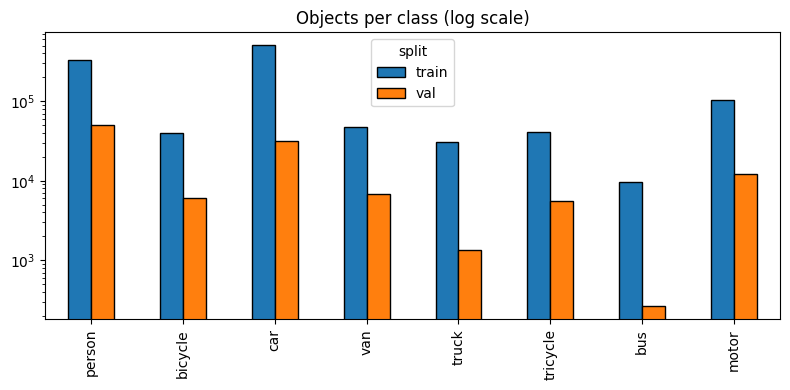

Objects, orig_category_id:
 {1: 266709, 2: 112304, 3: 46277, 4: 537122, 5: 53782, 6: 31857, 7: 32107, 8: 14729, 9: 9917, 10: 114844}
Ignored, orig_category_id:
 {0: 66363, 11: 1475}


In [ ]:
cls_counts = obj.groupby(["split", "cls"]).size().unstack(0).reindex(range(8)).fillna(0).astype(int)
cls_counts.index = CLASS_NAMES
cls_share = (cls_counts / cls_counts.sum() * 100).round(2)
display(pd.concat({"count": cls_counts, "share_%": cls_share}, axis=1))

cls_counts.plot.bar(figsize=(8, 4), logy=True, edgecolor="black")
plt.title("Objects per class (log scale)")
plt.tight_layout()
plt.show()

# Original 10-class VisDrone ids: what ended up as objects vs. ignored regions
if "orig_category_id" in obj.columns:
    print("Objects, orig_category_id:\n", obj["orig_category_id"].value_counts().sort_index().to_dict())
    print("Ignored, orig_category_id:\n", ign["orig_category_id"].value_counts().sort_index().to_dict())

**Note.** Car and person make up 75% of train objects, bus under 1%. Val leans towards person (44% vs 30%) and has only 264 bus boxes, so per-class AP for bus will be noisy. The 8 classes merge pedestrian + people and tricycle + awning-tricycle; the original `ignored regions` (0) and `others` (11) are stored as ignored.

### 2.3 Object sizes


size_bin,small,medium,large,median_size_px
cls,,,,
bicycle,21.6,75.6,2.8,43.9
bus,4.0,39.4,56.6,111.7
car,16.0,64.9,19.2,57.5
motor,31.4,66.8,1.7,39.8
person,37.5,61.7,0.7,36.7
tricycle,20.8,65.3,14.0,54.5
truck,9.1,57.5,33.4,73.9
van,19.5,63.8,16.7,51.3


Overall share (%):
size_bin
medium    64.0
small     24.4
large     11.6
Name: proportion, dtype: float64

Size quantiles (px): {0.01: 14.1, 0.05: 19.9, 0.25: 32.3, 0.5: 46.4, 0.75: 68.8, 0.95: 130.3, 0.99: 208.9}


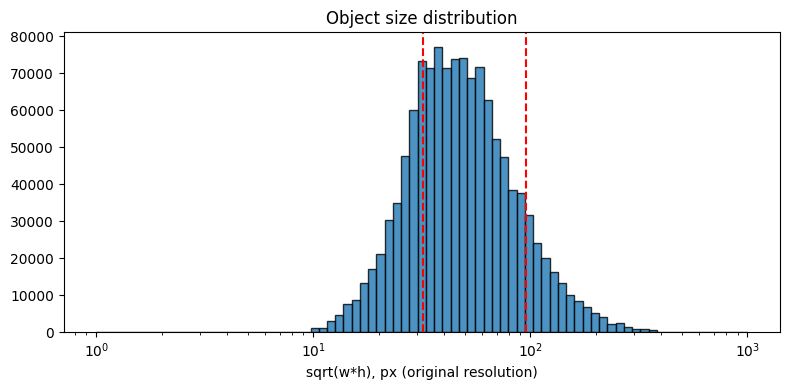

In [ ]:
# COCO size buckets on sqrt(area): small < 32 px, medium 32-96 px, large > 96 px
obj["size_bin"] = pd.cut(obj["size"], [0, 32, 96, np.inf], labels=["small", "medium", "large"])

size_share = (pd.crosstab(obj["cls"].map(dict(enumerate(CLASS_NAMES))), obj["size_bin"], normalize="index") * 100).round(1)
size_share["median_size_px"] = obj.groupby(obj["cls"].map(dict(enumerate(CLASS_NAMES))))["size"].median().round(1)
display(size_share)
print("Overall share (%):")
print((obj["size_bin"].value_counts(normalize=True) * 100).round(1))
print("\nSize quantiles (px):", obj["size"].quantile([.01, .05, .25, .5, .75, .95, .99]).round(1).to_dict())

plt.figure(figsize=(8, 4))
plt.hist(obj["size"], bins=np.logspace(0, 3, 80), edgecolor="black", alpha=0.8)
plt.xscale("log")
for t in (32, 96):
    plt.axvline(t, color="red", linestyle="--")
plt.xlabel("sqrt(w*h), px (original resolution)")
plt.title("Object size distribution")
plt.tight_layout()
plt.show()

**Note.** Only 24% of objects are COCO-small, but this is measured in original pixels and hides what the model sees after resizing (see 2.10). Only bus and truck have a sizable share of large objects.


### 2.4 Objects per frame

         count  mean   std  min   25%   50%   75%    max
split                                                   
train  24201.0  45.7  31.6  0.0  22.0  43.0  57.0  180.0
val     2846.0  40.1  26.8  8.0  16.0  37.0  51.8  116.0
Frames with 0 objects: 3
Frames with >100 objects (%): 7.5


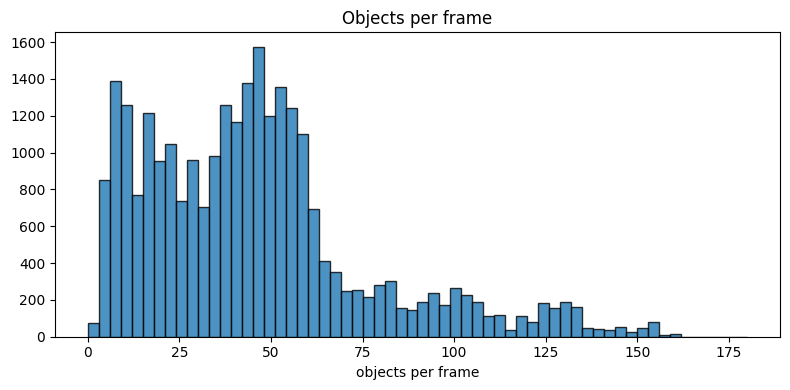

In [ ]:
imgs["n_obj"] = obj.groupby("uid").size().reindex(imgs["uid"]).fillna(0).astype(int).values
print(imgs.groupby("split")["n_obj"].describe().round(1))
print("Frames with 0 objects:", (imgs["n_obj"] == 0).sum())
print("Frames with >100 objects (%):", round((imgs["n_obj"] > 100).mean() * 100, 1))

plt.figure(figsize=(8, 4))
plt.hist(imgs["n_obj"], bins=60, edgecolor="black", alpha=0.8)
plt.xlabel("objects per frame")
plt.title("Objects per frame")
plt.tight_layout()
plt.show()

**Note.** Density is uneven and reaches 180 objects, above the default limit of 100 detections per image in torchvision Faster R-CNN and FCOS and in COCO `maxDets`, so these limits must be raised. The 3 empty frames stay as negatives.


### 2.5 Variation across clips

frames  width  height  mean_obj  max_obj  \
split video                                                          
train uav0000218_00001_v     225   2688    1512      5.15        7   
      uav0000266_04830_v     116   2688    1512      6.09        7   
      uav0000263_03289_v     725   1904    1071      6.46       11   
      uav0000266_03598_v     548   2688    1512      6.47       10   
      uav0000099_02109_v    1255   1344     756      7.14       13   
...                          ...    ...     ...       ...      ...   
      uav0000150_02310_v     348   2688    1512    108.89      174   
      uav0000072_04488_v      85   1904    1071    110.38      124   
      uav0000124_00944_v     398   2688    1512    124.57      134   
      uav0000126_00001_v     412   2688    1512    132.22      166   
      uav0000138_00000_v     213   2688    1512    142.96      156   

                          median_size  small_share  
split video                                         
train uav0000218_00001_v        62.14         0.02  
      uav0000266_04830_v        81.58         0.00  
      uav0000263_03289_v        54.85         0.11  
      uav0000266_03598_v        80.92         0.00  
      uav0000099_02109_v        37.08         0.29  
...                               ...          ...  
      uav0000150_02310_v        60.03         0.05  
      uav0000072_04488_v        45.83         0.15  
      uav0000124_00944_v        46.31         0.24  
      uav0000126_00001_v        48.37         0.24  
      uav0000138_00000_v        45.38         0.17  

[63 rows x 7 columns]

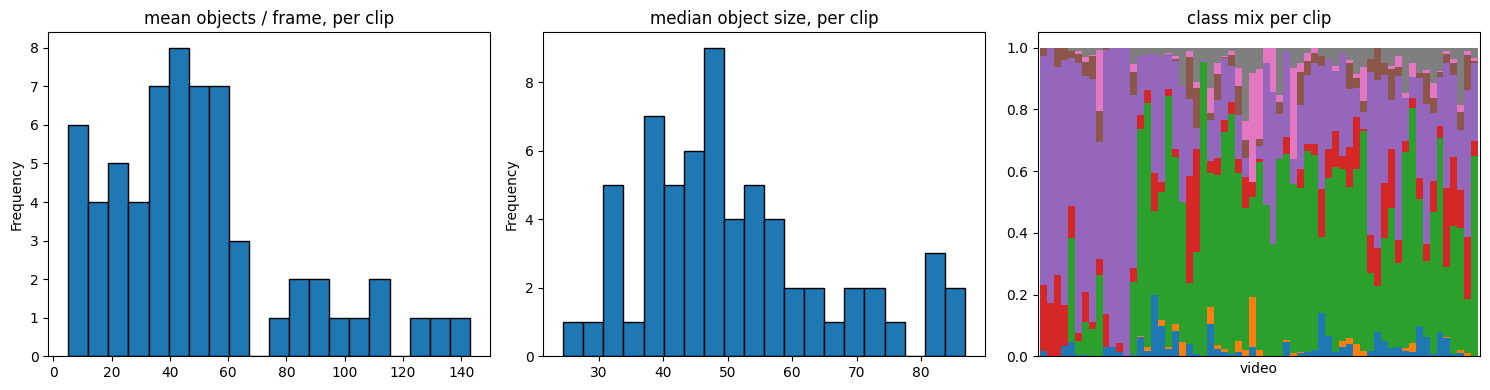

In [ ]:
obj["is_small"] = obj["size"] < 32
clip_df = imgs.groupby(["split", "video"]).agg(
    frames=("uid", "size"), width=("width", "first"), height=("height", "first"),
    mean_obj=("n_obj", "mean"), max_obj=("n_obj", "max"),
)
clip_df["median_size"] = obj.groupby(["split", "video"])["size"].median()
clip_df["small_share"] = obj.groupby(["split", "video"])["is_small"].mean()
display(clip_df.round(2).sort_values("mean_obj"))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
clip_df["mean_obj"].plot.hist(bins=20, ax=ax[0], edgecolor="black"); ax[0].set_title("mean objects / frame, per clip")
clip_df["median_size"].plot.hist(bins=20, ax=ax[1], edgecolor="black"); ax[1].set_title("median object size, per clip")
mix = pd.crosstab(obj["video"], obj["cls"].map(dict(enumerate(CLASS_NAMES))), normalize="index")
mix.plot.bar(stacked=True, ax=ax[2], legend=False, width=1.0); ax[2].set_title("class mix per clip"); ax[2].set_xticks([])
plt.tight_layout()
plt.show()

**Note.** Clips differ far more than frames do: 5 to 143 objects per frame, and about 15 clips contain almost no cars. Scene type therefore follows the clip, which is why splits must be made by clip and why 7 val clips give a noisy estimate.


### 2.6 Ignored regions

In [ ]:
ign["area_frac"] = ign["w"] * ign["h"] / (ign["width"] * ign["height"])
print("Frames with >=1 ignored region (%):", round(ign["uid"].nunique() / len(imgs) * 100, 1))
print("Ignored regions per frame (frames that have them):\n", ign.groupby("uid").size().describe().round(2))
print("\nArea fraction of one ignored region:\n", ign["area_frac"].describe().round(4))

frame_ign = ign.groupby("uid")["area_frac"].sum().reindex(imgs["uid"]).fillna(0)
print("\nTotal ignored area per frame (share of image), all frames:\n", frame_ign.describe().round(4))

Frames with >=1 ignored region (%): 72.2
Ignored regions per frame (frames that have them):
 count    19524.00
mean         3.47
std          3.17
min          1.00
25%          1.00
50%          2.00
75%          5.00
max         22.00
dtype: float64

Area fraction of one ignored region:
 count    67838.0000
mean         0.0093
std          0.0140
min          0.0001
25%          0.0020
50%          0.0045
75%          0.0105
max          0.1531
Name: area_frac, dtype: float64

Total ignored area per frame (share of image), all frames:
 count    27047.0000
mean         0.0233
std          0.0393
min          0.0000
25%          0.0000
50%          0.0097
75%          0.0276
max          0.3853
Name: area_frac, dtype: float64


**Note.** Ignored regions appear in 72% of frames but cover only 2.3% of the area on average. They may contain unlabeled objects, so in training they are filled with the mean colour and the model is not penalised there. For evaluation they stay in the COCO file as `iscrowd=1`, and val images are left unchanged.


### 2.7 Truncation / occlusion

In [ ]:
for c in ("occlusion", "truncation"):
    if c in obj.columns:
        print(c, (obj[c].value_counts(normalize=True).sort_index() * 100).round(1).to_dict())

occlusion {0.0: 53.1, 1.0: 41.5, 2.0: 5.5}
truncation {0.0: 95.6, 1.0: 4.4}


**Note.** 47% of objects are at least partly occluded, so NMS can remove true neighbours; Soft-NMS is worth testing. Truncation is rare.


### 2.8 Image resolutions (train / val / test)

In [ ]:
test_df = pd.read_csv(DATA / "test_images.csv")
res = pd.concat({
    "train+val": imgs.groupby(["width", "height"]).size(),
    "test": test_df.groupby(["width", "height"]).size(),
}, axis=1).fillna(0).astype(int)
display(res)
print("Test clips:", test_df["clip"].nunique(), "| frames:", len(test_df))

,,train+val,test
width,height,,
1344,756,6472,441
1360,765,962,0
1904,1071,13354,0
1920,1080,721,991
2688,1512,3738,0
2720,1530,822,0
3840,2160,978,0
680,382,0,321
960,540,0,279


Test clips: 48 | frames: 3811


**Note.** Test is lower-resolution than val: 66% of test frames have a long side of at most 1360, while 55% of val frames have at least 2688, and 3840 appears only in one val clip. Val images are sharper than upscaled test frames, so scale jitter and mild blur are used in training.


### 2.9 Aspect ratios and anchor sizes

In [ ]:
obj["ar"] = obj["w"] / obj["h"]
ar = obj.groupby(obj["cls"].map(dict(enumerate(CLASS_NAMES))))["ar"].describe(percentiles=[.05, .5, .95]).round(2)
display(ar[["5%", "50%", "95%"]])

# k-means on box (w, h) after resizing the longer image side to INPUT px (YOLOv2-style anchor grounding)
from sklearn.cluster import KMeans

INPUT = 1024
scale = INPUT / np.maximum(obj["width"], obj["height"])
wh = np.stack([obj["w"] * scale, obj["h"] * scale], axis=1)
wh = wh[np.random.RandomState(RANDOM_STATE).choice(len(wh), min(len(wh), 200_000), replace=False)]
km = KMeans(n_clusters=9, n_init=5, random_state=RANDOM_STATE).fit(np.log(wh))
anchors = np.exp(km.cluster_centers_)
anchors = anchors[np.argsort(anchors.prod(axis=1))]
print(f"k-means anchors (w, h) at input {INPUT}:\n", anchors.round(1))

,5%,50%,95%
cls,,,
bicycle,0.46,0.93,1.91
bus,0.57,1.05,3.58
car,0.73,1.26,2.68
motor,0.46,0.80,1.70
person,0.34,0.50,0.90
tricycle,0.60,1.06,2.00
truck,0.70,1.08,2.55
van,0.65,1.13,2.05


k-means anchors (w, h) at input 1024:
 [[  7.3  12.4]
 [ 16.1  12.6]
 [ 12.2  23.6]
 [ 25.4  19.2]
 [ 20.4  35.8]
 [ 42.2  25.2]
 [ 38.1  52.9]
 [ 74.4  39.1]
 [100.2  81. ]]


**Note.** Median aspect ratios are close to 0.5 for person and 1 for vehicles, so ratios of 0.5, 1 and 2 cover them. K-means sizes span 7-100 px at input 1024, below the torchvision default of 32-512 px, so smaller anchors are needed. They scale linearly with input size.


### 2.10 Input resolution: how small do objects become?

In [ ]:
max_side = np.maximum(obj["width"], obj["height"])
rows = []
for L in [640, 800, 1024, 1280, 1536, 1920]:
    s = obj["size"] * L / max_side
    rows.append({"input (long side)": L, "<8 px (%)": (s < 8).mean() * 100,
                 "<16 px (%)": (s < 16).mean() * 100, "<32 px (%)": (s < 32).mean() * 100,
                 "median size px": s.median()})
display(pd.DataFrame(rows).round(1).set_index("input (long side)"))

,<8 px (%),<16 px (%),<32 px (%),median size px
input (long side),,,,
640,9.7,53.6,89.2,15.3
800,3.9,36.4,81.9,19.1
1024,1.4,19.9,68.9,24.5
1280,0.6,9.7,53.6,30.6
1536,0.2,4.8,39.4,36.7
1920,0.0,1.8,23.5,45.9


**Note.** At 640, over half of the objects are under 16 px, which is too small to keep. 1280 is the starting input, leaving 10% under 16 px; 1536 is tested if memory allows. This is also why a high-resolution feature level (stride 4) is useful.


### 2.11 Conversion check: YOLO labels vs COCO

In [ ]:
from scipy.spatial.distance import cdist

def frame_paths(split, row):
    stem = Path(row["file_name"]).stem
    base = DATA / split
    return base / "images" / row["video"] / f"{stem}.jpg", base / "labels" / row["video"] / f"{stem}.txt", base / "ignore" / row["video"] / f"{stem}.txt"

def read_txt(path, ncols):
    if not path.exists() or path.stat().st_size == 0:
        return np.zeros((0, ncols))
    return np.loadtxt(path, ndmin=2)

def yolo_to_xywh(a, W, H, has_cls=True):
    off = 1 if has_cls else 0
    cx, cy, w, h = (a[:, off + i] for i in range(4))
    return np.stack([(cx - w / 2) * W, (cy - h / 2) * H, w * W, h * H], axis=1)

obj_by_uid = {u: g for u, g in obj.groupby("uid")}
ign_by_uid = {u: g for u, g in ign.groupby("uid")}

max_diff, cls_bad, ign_bad = 0.0, 0, 0
sample = imgs.sample(400, random_state=RANDOM_STATE)

for _, row in sample.iterrows():
    _, lab_p, ign_p = frame_paths(row["split"], row)
    y = read_txt(lab_p, 5)
    c = obj_by_uid.get(row["uid"])
    if len(y) != (len(c) if c is not None else 0):
        cls_bad += 1
    elif len(y):
        y_xywh = yolo_to_xywh(y, row["width"], row["height"])
        for k in np.unique(y[:, 0]):  # box order differs between the files, so match nearest box per class
            a = y_xywh[y[:, 0] == k]
            b = c.loc[c["cls"] == k, ["x", "y", "w", "h"]].values
            if len(a) != len(b):
                cls_bad += 1
                continue
            max_diff = max(max_diff, cdist(a, b, "chebyshev").min(axis=1).max())
    g = ign_by_uid.get(row["uid"])
    ign_bad += len(read_txt(ign_p, 4)) != (len(g) if g is not None else 0)

print(f"Checked {len(sample)} frames: max box diff={max_diff:.2f} px, "
      f"class count mismatches={cls_bad}, ignore count mismatches={ign_bad}")

# Why ignored regions repeat in the COCO file: distinct category_ids per unique region
coco = json.load(open(DATA / "val" / "annotations_coco.json"))
crowd = pd.DataFrame([a for a in coco["annotations"] if a["iscrowd"] == 1])
crowd["bbox"] = crowd["bbox"].map(tuple)
print("Distinct categories per ignored region:",
      crowd.groupby(["image_id", "bbox"])["category_id"].nunique().value_counts().to_dict())


Checked 400 frames: max box diff=0.00 px, class count mismatches=0, ignore count mismatches=0
Distinct categories per ignored region: {8: 3995}


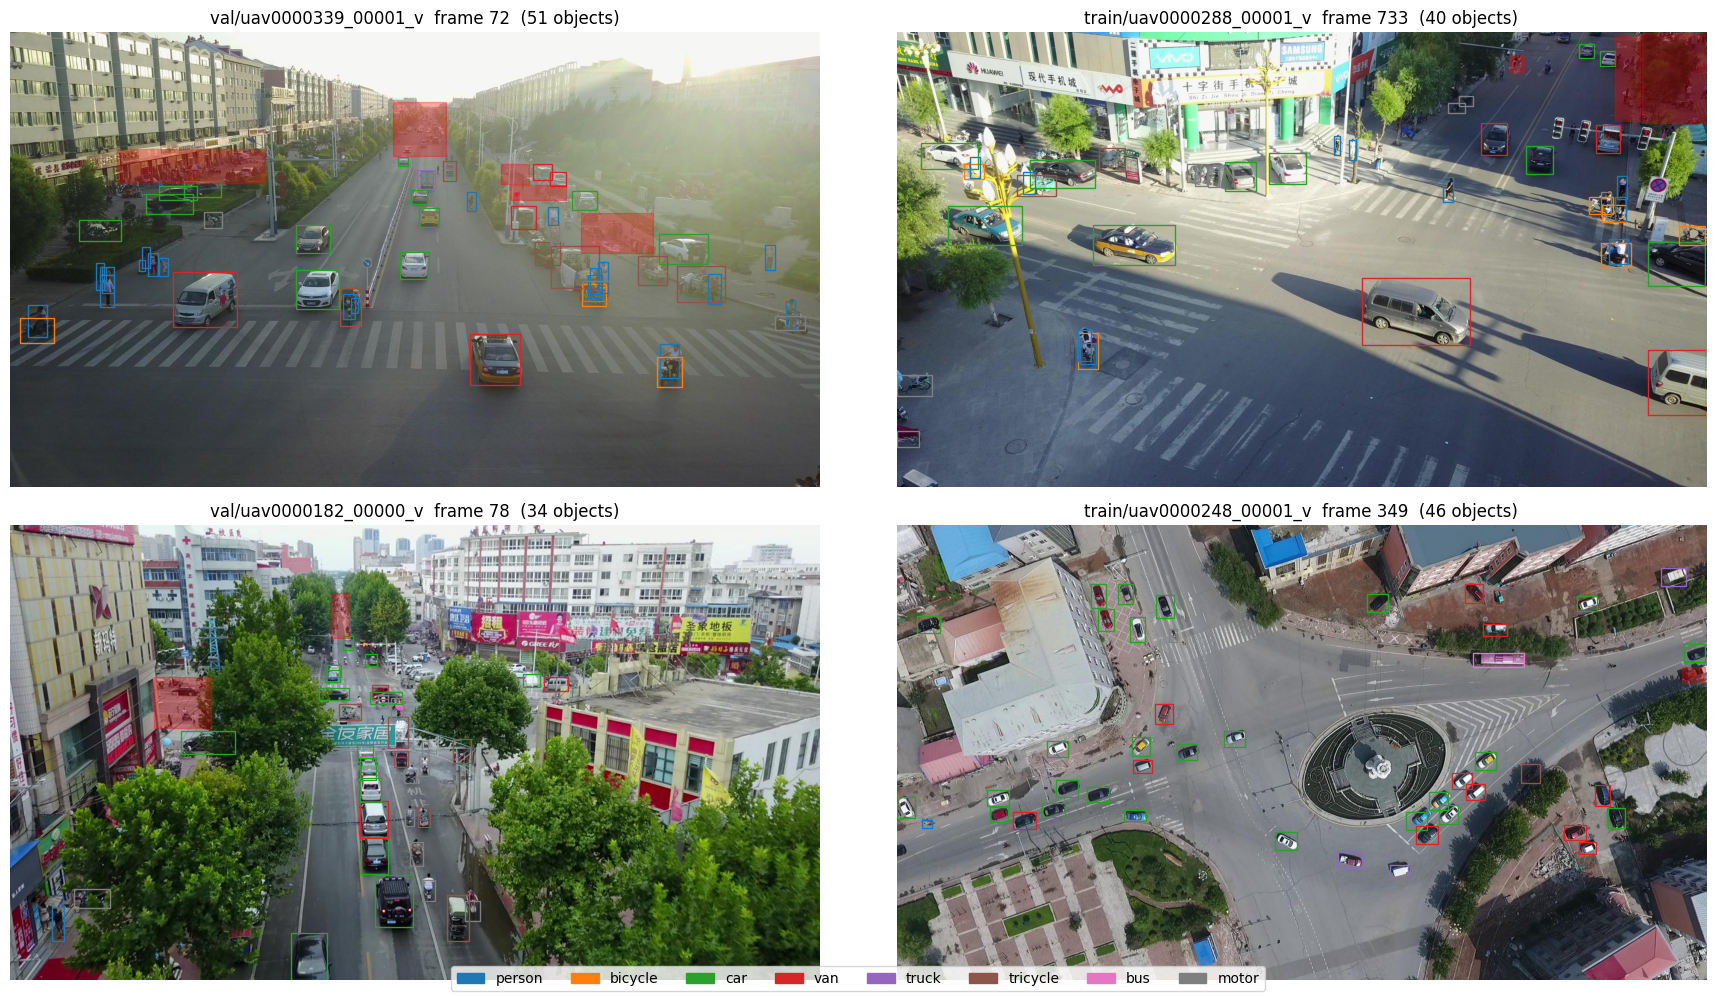

In [ ]:
# Visual check: GT boxes (coloured by class) and ignored regions (red) on random frames
from PIL import Image
import matplotlib.patches as patches

cmap = plt.get_cmap("tab10")
vis = imgs[imgs["n_obj"] > 0].sample(4, random_state=7)

fig, axes = plt.subplots(2, 2, figsize=(18, 10))
for ax, (_, row) in zip(axes.ravel(), vis.iterrows()):
    img_p, _, _ = frame_paths(row["split"], row)
    ax.imshow(Image.open(img_p))
    for _, o in obj_by_uid[row["uid"]].iterrows():
        ax.add_patch(patches.Rectangle((o.x, o.y), o.w, o.h, fill=False, edgecolor=cmap(int(o.cls)), linewidth=1))
    for _, g in ign_by_uid.get(row["uid"], pd.DataFrame()).iterrows():
        ax.add_patch(patches.Rectangle((g.x, g.y), g.w, g.h, facecolor="red", alpha=0.3, edgecolor="red"))
    ax.set_title(f'{row["split"]}/{row["video"]}  frame {row["frame_id"]}  ({row["n_obj"]} objects)')
    ax.axis("off")
handles = [patches.Patch(color=cmap(i), label=n) for i, n in enumerate(CLASS_NAMES)]
fig.legend(handles=handles, loc="lower center", ncol=8)
plt.tight_layout()
plt.show()

**Note.** After matching boxes by class, YOLO labels agree with the COCO file. The figure shows riders annotated twice (person + bicycle or motor), so NMS must stay class-wise.


### 2.12 Train / val split by clip


In [ ]:
train_clips = set(imgs[imgs.split == "train"].video)
val_clips = set(imgs[imgs.split == "val"].video)
print("Train clips:", len(train_clips), "| val clips:", len(val_clips), "| overlap:", train_clips & val_clips)
# Clips cut from one flight share a prefix (uav0000266_03598_v, uav0000266_04830_v), so check that too
flight = lambda clips: {c.split("_")[0] for c in clips}
print("Shared flights:", flight(train_clips) & flight(val_clips))
display(clip_df.loc["val"].round(2))

Train clips: 56 | val clips: 7 | overlap: set()
Shared flights: set()


,frames,width,height,mean_obj,max_obj,median_size,small_share
video,,,,,,,
uav0000086_00000_v,464,1344,756,49.78,71,39.82,0.29
uav0000117_02622_v,349,2720,1530,49.51,93,65.12,0.08
uav0000137_00458_v,233,2688,1512,103.38,116,73.18,0.01
uav0000182_00000_v,363,1344,756,48.68,87,32.45,0.49
uav0000268_05773_v,978,3840,2160,13.88,21,48.43,0.14
uav0000305_00000_v,184,1904,1071,34.73,42,77.05,0.11
uav0000339_00001_v,275,1904,1071,43.74,52,48.54,0.21


**Note.** The provided split has no shared clips. Grouping for any further folds uses the flight prefix, not the clip name. One 3840 clip holds 34% of val frames, so results are also worth checking per clip.


### 2.13 Frame step: how similar are consecutive frames?

In [ ]:
# Same object (track_id) in frame t and t+k: mean IoU of its box
tr = obj[(obj["split"] == "train") & (obj["track_id"] >= 0)][["video", "track_id", "frame_id", "x", "y", "w", "h"]]

def box_iou(a, b):
    ix = np.clip(np.minimum(a.x + a.w, b.x + b.w) - np.maximum(a.x, b.x), 0, None)
    iy = np.clip(np.minimum(a.y + a.h, b.y + b.h) - np.maximum(a.y, b.y), 0, None)
    inter = ix * iy
    return inter / (a.w * a.h + b.w * b.h - inter)

rows = []
for k in [1, 2, 3, 5, 10, 20]:
    nxt = tr.copy(); nxt["frame_id"] -= k
    m = tr.merge(nxt, on=["video", "track_id", "frame_id"], suffixes=("", "_k"))
    b = m[["x_k", "y_k", "w_k", "h_k"]].rename(columns=lambda c: c[:-2])
    iou = box_iou(m[["x", "y", "w", "h"]], b)
    rows.append({"step k": k, "mean IoU": iou.mean(), "share IoU>0.5 (%)": (iou > 0.5).mean() * 100})
display(pd.DataFrame(rows).round(3).set_index("step k"))

,mean IoU,share IoU>0.5 (%)
step k,,
1,0.851,95.858
2,0.752,85.981
3,0.676,75.494
5,0.565,59.375
10,0.408,39.291
20,0.280,26.084


**Note.** Boxes shift quickly with the step: mean IoU falls from 0.85 at step 1 to 0.57 at step 5. Step 5 keeps about 4,800 train frames, removing near-duplicates while staying affordable. Clip length varies from 85 to 1,255 frames, so a per-clip cap stops long clips from dominating.


### 2.14 Preprocessing decisions
- Ignored regions: filled with the mean colour in train, kept as `iscrowd=1` in evaluation.
- Split: the provided train / val split, by clip; no flights are shared.
- Frames: every 5th frame, seed 42, with a per-clip cap.
- Resize: long side 1280, aspect ratio kept.
- Normalization: ImageNet mean and std for pretrained backbones.
- Augmentation: horizontal flip, scale jitter, colour jitter, mild blur.
- Detection limit: at least 300 per image.

## 3. Two-stage anchor-based: Faster R-CNN

**Setup.** Faster R-CNN with ResNet-50 FPN, pretrained on COCO. Input long side 1280, every 5th frame, up to 150 frames per clip, 6 epochs, batch 4, SGD with OneCycle schedule. Anchors follow the k-means sizes from 2.9. All experiments use the same frames and evaluation.

In [ ]:
!pip install -q pycocotools

import contextlib, io, time
from PIL import Image, ImageDraw
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.anchor_utils import AnchorGenerator
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

INPUT = 1280          # long side, from 2.10
STEP = 5              # frame step, from 2.13
MAX_PER_CLIP = 150    # stops long clips from dominating
BATCH = 4
EPOCHS = 6
LR = 0.005
MEAN_COLOUR = (124, 116, 104)  # ImageNet mean

# Lookups by frame, so a new session needs only Setup and 2.1
boxes_by_uid = {u: g[["x", "y", "w", "h", "cls"]].values for u, g in obj.groupby("uid")}
ignore_by_uid = {u: g[["x", "y", "w", "h"]].values for u, g in ign.groupby("uid")}

def pick_frames(split):
    df = imgs[imgs["split"] == split].sort_values(["video", "frame_id"])
    return df[df.groupby("video").cumcount() % STEP == 0]

val_df = pick_frames("val")
train_df = pick_frames("train").sample(frac=1, random_state=RANDOM_STATE).groupby("video").head(MAX_PER_CLIP)
print("Train frames:", len(train_df), "| val frames:", len(val_df))

Train frames: 4560 | val frames: 571


In [ ]:
colour_aug = T.Compose([
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    T.RandomApply([T.GaussianBlur(5, sigma=(0.5, 1.5))], p=0.2),
])

class DroneFrames(Dataset):
    def __init__(self, frames, train):
        self.frames, self.train = frames.reset_index(drop=True), train

    def __len__(self):
        return len(self.frames)

    def __getitem__(self, i):
        row = self.frames.iloc[i]
        path = DATA / row["split"] / "images" / row["video"] / f'{Path(row["file_name"]).stem}.jpg'
        img = Image.open(path).convert("RGB")
        if not self.train:  # the model resizes val frames and maps boxes back itself
            return T.functional.to_tensor(img), {"image_id": int(row["id"])}

        # Resize first: faster loading, and blur is not lost in later downscaling
        scale = INPUT / max(img.size)
        img = img.resize((round(img.width * scale), round(img.height * scale)))

        # Hide ignored regions (2.6)
        draw = ImageDraw.Draw(img)
        for x, y, w, h in ignore_by_uid.get(row["uid"], []):
            draw.rectangle([x * scale, y * scale, (x + w) * scale, (y + h) * scale], fill=MEAN_COLOUR)

        # COCO xywh -> xyxy at the new scale, labels 1-8 (0 is background)
        a = boxes_by_uid.get(row["uid"], np.zeros((0, 5)))
        boxes = a[:, :4] * scale
        boxes[:, 2:] += boxes[:, :2]
        boxes[:, [0, 2]] = boxes[:, [0, 2]].clip(0, img.width)
        boxes[:, [1, 3]] = boxes[:, [1, 3]].clip(0, img.height)
        labels = a[:, 4] + 1

        if np.random.rand() < 0.5:  # horizontal flip
            img = img.transpose(Image.FLIP_LEFT_RIGHT)
            boxes[:, [0, 2]] = img.width - boxes[:, [2, 0]]

        keep = (boxes[:, 2] - boxes[:, 0] >= 1) & (boxes[:, 3] - boxes[:, 1] >= 1)  # torchvision rejects empty boxes
        target = {"boxes": torch.as_tensor(boxes[keep], dtype=torch.float32),
                  "labels": torch.as_tensor(labels[keep], dtype=torch.int64)}
        return T.functional.to_tensor(colour_aug(img)), target

def collate(batch):
    return tuple(zip(*batch))

train_loader = DataLoader(DroneFrames(train_df, True), batch_size=BATCH, shuffle=True,
                          num_workers=2, collate_fn=collate, drop_last=True)
val_loader = DataLoader(DroneFrames(val_df, False), batch_size=1, num_workers=2, collate_fn=collate)

In [ ]:
def build_model(rpn_proposals=1000):
    model = fasterrcnn_resnet50_fpn(
        weights="DEFAULT",            # pretrained on COCO
        min_size=(576, 648, 720),     # random scale in training, 720 in evaluation
        max_size=INPUT,
        rpn_post_nms_top_n_test=rpn_proposals,
        box_detections_per_img=300,   # 2.4: frames reach 180 objects
        box_score_thresh=0.01,
    )
    # Smaller anchors from the k-means in 2.9, one size per FPN level
    model.rpn.anchor_generator = AnchorGenerator(
        sizes=((12,), (24,), (48,), (96,), (192,)),
        aspect_ratios=((0.5, 1.0, 2.0),) * 5,
    )
    # New classification head: 8 classes + background
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, 9)
    return model

build_frcnn = build_model  # cell below rebinds build_model to RetinaNet

In [ ]:
# Ground truth for the selected val frames. Ignored regions stay here as iscrowd=1
gt_data = json.load(open(DATA / "val" / "annotations_coco.json"))
val_ids = set(val_df["id"])
gt_data["images"] = [x for x in gt_data["images"] if x["id"] in val_ids]
gt_data["annotations"] = [x for x in gt_data["annotations"] if x["image_id"] in val_ids]
for x in gt_data["annotations"]:
    x["area"] = x["bbox"][2] * x["bbox"][3]

with contextlib.redirect_stdout(io.StringIO()):
    coco_gt = COCO()
    coco_gt.dataset = gt_data
    coco_gt.createIndex()

def sync():
    if device == "cuda":
        torch.cuda.synchronize()

@torch.no_grad()
def evaluate(model):
    model.eval()
    results, seconds = [], 0.0
    for images, targets in val_loader:
        images = [x.to(device) for x in images]
        sync(); start = time.perf_counter()
        outputs = model(images)
        sync(); seconds += time.perf_counter() - start
        for target, out in zip(targets, outputs):
            boxes = out["boxes"].clone()
            boxes[:, 2:] -= boxes[:, :2]  # xyxy -> xywh
            for box, score, label in zip(boxes.tolist(), out["scores"].tolist(), out["labels"].tolist()):
                results.append({"image_id": target["image_id"], "category_id": label, "bbox": box, "score": score})

    metrics = {"mAP": 0.0, "AP50": 0.0, "AP_small": 0.0, "fps": len(val_df) / seconds}
    if results:
        with contextlib.redirect_stdout(io.StringIO()):
            ev = COCOeval(coco_gt, coco_gt.loadRes(results), "bbox")
            ev.params.maxDets = [1, 100, 300]  # the default 100 is below our densest frames
            ev.evaluate(); ev.accumulate(); ev.summarize()
        metrics.update(mAP=ev.stats[0], AP50=ev.stats[1], AP_small=ev.stats[3])
    return metrics

In [ ]:
def run(name, epochs=EPOCHS, **model_args):
    if exists(name):  # already trained: load the saved results from Drive
        return load(name)

    torch.manual_seed(RANDOM_STATE)
    np.random.seed(RANDOM_STATE)
    model = build_model(**model_args).to(device)
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.SGD(params, lr=LR, momentum=0.9, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=LR, total_steps=epochs * len(train_loader), pct_start=0.05, cycle_momentum=False)
    scaler = torch.amp.GradScaler(device, enabled=device == "cuda")

    history, best = [], -1.0
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        for images, targets in train_loader:
            images = [x.to(device) for x in images]
            targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
            with torch.amp.autocast(device, enabled=device == "cuda"):
                loss = sum(model(images, targets).values())
            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            total_loss += loss.item()

        metrics = evaluate(model)
        metrics.update(epoch=epoch, loss=total_loss / len(train_loader))
        history.append(metrics)
        print({k: round(v, 4) for k, v in metrics.items()})
        if metrics["mAP"] > best:  # keep the best epoch on Drive
            best = metrics["mAP"]
            torch.save(model.state_dict(), CKPT / f"{name}.pt")

    save(name, history)
    return history

In [ ]:
baseline = run("frcnn_base")
pd.DataFrame(baseline).set_index("epoch").round(4)

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:02<00:00, 65.8MB/s]
/tmp/ipykernel_1544/1132220931.py:27: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


{'mAP': np.float64(0.1789), 'AP50': np.float64(0.3998), 'AP_small': np.float64(0.0775), 'fps': 5.6906, 'epoch': 1, 'loss': 1.0449}
{'mAP': np.float64(0.1868), 'AP50': np.float64(0.4099), 'AP_small': np.float64(0.0903), 'fps': 5.7743, 'epoch': 2, 'loss': 0.8597}
{'mAP': np.float64(0.1928), 'AP50': np.float64(0.4208), 'AP_small': np.float64(0.0906), 'fps': 5.7754, 'epoch': 3, 'loss': 0.7916}
{'mAP': np.float64(0.1937), 'AP50': np.float64(0.4112), 'AP_small': np.float64(0.0967), 'fps': 5.7694, 'epoch': 4, 'loss': 0.746}
{'mAP': np.float64(0.2009), 'AP50': np.float64(0.4281), 'AP_small': np.float64(0.1027), 'fps': 5.7712, 'epoch': 5, 'loss': 0.7166}
{'mAP': np.float64(0.2023), 'AP50': np.float64(0.4271), 'AP_small': np.float64(0.1019), 'fps': 5.7411, 'epoch': 6, 'loss': 0.7023}


,mAP,AP50,AP_small,fps,loss
epoch,,,,,
1,0.1789,0.3998,0.0775,5.6906,1.0449
2,0.1868,0.4099,0.0903,5.7743,0.8597
3,0.1928,0.4208,0.0906,5.7754,0.7916
4,0.1937,0.4112,0.0967,5.7694,0.7460
5,0.2009,0.4281,0.1027,5.7712,0.7166
6,0.2023,0.4271,0.1019,5.7411,0.7023


In [ ]:
def eval_saved(name, **model_args):
    model = build_model(**model_args).to(device)
    model.load_state_dict(torch.load(CKPT / f"{name}.pt", map_location=device))
    return evaluate(model)

proposal_results = {p: eval_saved("frcnn_base", rpn_proposals=p) for p in (500, 1000, 2000)}
save("frcnn_proposals", proposal_results)
pd.DataFrame(proposal_results).T.rename_axis("proposals").round(4)

,mAP,AP50,AP_small,fps
proposals,,,,
500,0.2000,0.4211,0.1013,6.1579
1000,0.2023,0.4271,0.1019,5.7236
2000,0.2026,0.4265,0.1019,5.4227


In [ ]:
import torch.nn.functional as F
import torchvision.models.detection.roi_heads as roi_heads
from torchvision.ops import generalized_box_iou_loss

GIOU_WEIGHT = 10  # GIoU values are much larger than Smooth L1; same weight as MMDetection

def deltas_to_boxes(d):
    # Turn predicted shifts into a box, relative to a proposal of size 1 (IoU does not change)
    d = d.float()
    cx, cy = d[:, 0] / 10, d[:, 1] / 10
    w, h = torch.exp((d[:, 2] / 5).clamp(max=4)), torch.exp((d[:, 3] / 5).clamp(max=4))
    return torch.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], dim=1)

def giou_fastrcnn_loss(class_logits, box_regression, labels, regression_targets):
    labels = torch.cat(labels)
    regression_targets = torch.cat(regression_targets)
    class_loss = F.cross_entropy(class_logits, labels)

    positive = torch.where(labels > 0)[0]
    box_regression = box_regression.reshape(len(labels), -1, 4)
    pred = deltas_to_boxes(box_regression[positive, labels[positive]])
    target = deltas_to_boxes(regression_targets[positive])
    box_loss = GIOU_WEIGHT * generalized_box_iou_loss(pred, target, reduction="sum") / labels.numel()
    return class_loss, box_loss

original_loss = roi_heads.fastrcnn_loss
roi_heads.fastrcnn_loss = giou_fastrcnn_loss  # replace Smooth L1 only for this run
try:
    giou = run("frcnn_giou")
finally:
    roi_heads.fastrcnn_loss = original_loss

best = lambda history: max(history, key=lambda r: r["mAP"])
pd.DataFrame({"Smooth L1": best(baseline), "GIoU": best(giou)}).T.round(4)

,mAP,AP50,AP_small,fps,epoch,loss
Smooth L1,0.2023,0.4271,0.1019,5.7411,6.0,0.7023
GIoU,0.2009,0.4262,0.1018,5.7335,6.0,0.8299


In [ ]:
from torchvision.ops import box_iou

model = build_model().to(device)
model.load_state_dict(torch.load(CKPT / "frcnn_base.pt", map_location=device))
model.eval()

SCORE = 0.5  # keep confident predictions only
val_rows = val_df.set_index("id")
errors, frames = [], {}

def in_ignored(boxes, regions):
    cx, cy = (boxes[:, 0] + boxes[:, 2]) / 2, (boxes[:, 1] + boxes[:, 3]) / 2
    inside = torch.zeros(len(boxes), dtype=torch.bool)
    for x, y, w, h in regions:
        inside |= (cx >= x) & (cx <= x + w) & (cy >= y) & (cy <= y + h)
    return inside

with torch.no_grad():
    for images, targets in val_loader:
        out = model([images[0].to(device)])[0]
        keep = out["scores"] >= SCORE
        pred_boxes, pred_labels = out["boxes"][keep].cpu(), out["labels"][keep].cpu()

        row = val_rows.loc[targets[0]["image_id"]]
        a = boxes_by_uid.get(row["uid"], np.zeros((0, 5)))
        gt_boxes = torch.tensor(a[:, :4], dtype=torch.float32)
        gt_boxes[:, 2:] += gt_boxes[:, :2]
        gt_labels = torch.tensor(a[:, 4], dtype=torch.int64) + 1
        iou = box_iou(gt_boxes, pred_boxes)

        scale = INPUT / max(row["width"], row["height"])
        status = []
        for i in range(len(gt_boxes)):
            best = iou[i].max().item() if len(pred_boxes) else 0.0
            same = iou[i][pred_labels == gt_labels[i]]
            if len(same) and same.max() >= 0.5:
                result = "found"
            elif best >= 0.5:
                result = "wrong class"
            elif best >= 0.2:
                result = "poor box"
            else:
                result = "missed"
            status.append(result)
            errors.append({"video": row["video"], "cls": CLASS_NAMES[gt_labels[i] - 1], "result": result,
                           "pred_cls": CLASS_NAMES[pred_labels[iou[i].argmax()] - 1] if result == "wrong class" else None,
                           "size": np.sqrt(a[i, 2] * a[i, 3]) * scale})

        is_extra = (iou.max(dim=0).values < 0.1 if len(gt_boxes) else torch.ones(len(pred_boxes), dtype=torch.bool))
        is_extra &= ~in_ignored(pred_boxes, ignore_by_uid.get(row["uid"], []))
        frames[targets[0]["image_id"]] = (gt_boxes, status, pred_boxes[is_extra])

err = pd.DataFrame(errors)
save("frcnn_errors", err)
err["size_bin"] = pd.cut(err["size"], [0, 16, 32, 96, np.inf], labels=["<16", "16-32", "32-96", ">96"])

display((pd.crosstab(err["size_bin"], err["result"], normalize="index") * 100).round(1))
display((pd.crosstab(err["cls"], err["result"], normalize="index") * 100).round(1))
display((pd.crosstab(err["video"], err["result"], normalize="index") * 100).round(1))
print("Most common class mix-ups:")
print(err[err["result"] == "wrong class"].groupby(["cls", "pred_cls"]).size().nlargest(5))
print("False detections per frame:", round(np.mean([len(f[2]) for f in frames.values()]), 2))

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:03<00:00, 50.9MB/s]


result,found,missed,poor box,wrong class
size_bin,,,,
<16,7.0,75.8,12.6,4.6
16-32,52.8,24.4,14.5,8.3
32-96,72.7,9.8,8.8,8.7
>96,90.8,2.2,0.2,6.7


result,found,missed,poor box,wrong class
cls,,,,
bicycle,31.9,6.9,21.3,39.9
bus,3.8,26.4,0.0,69.8
car,63.5,29.2,4.6,2.7
motor,44.3,28.6,13.3,13.8
person,70.1,13.8,15.1,1.1
tricycle,39.2,32.8,8.0,20.0
truck,46.9,37.3,8.1,7.7
van,33.8,24.9,5.3,36.1


result,found,missed,poor box,wrong class
video,,,,
uav0000086_00000_v,77.0,8.5,14.1,0.4
uav0000117_02622_v,63.5,15.7,15.3,5.5
uav0000137_00458_v,71.0,7.3,9.9,11.8
uav0000182_00000_v,50.3,24.2,11.0,14.5
uav0000268_05773_v,16.2,74.0,2.1,7.7
uav0000305_00000_v,68.0,20.5,3.0,8.5
uav0000339_00001_v,54.2,17.7,17.6,10.6


Most common class mix-ups:
cls      pred_cls
van      car         452
bicycle  motor       329
motor    person      245
bicycle  person      139
car      van         108
dtype: int64
False detections per frame: 4.45


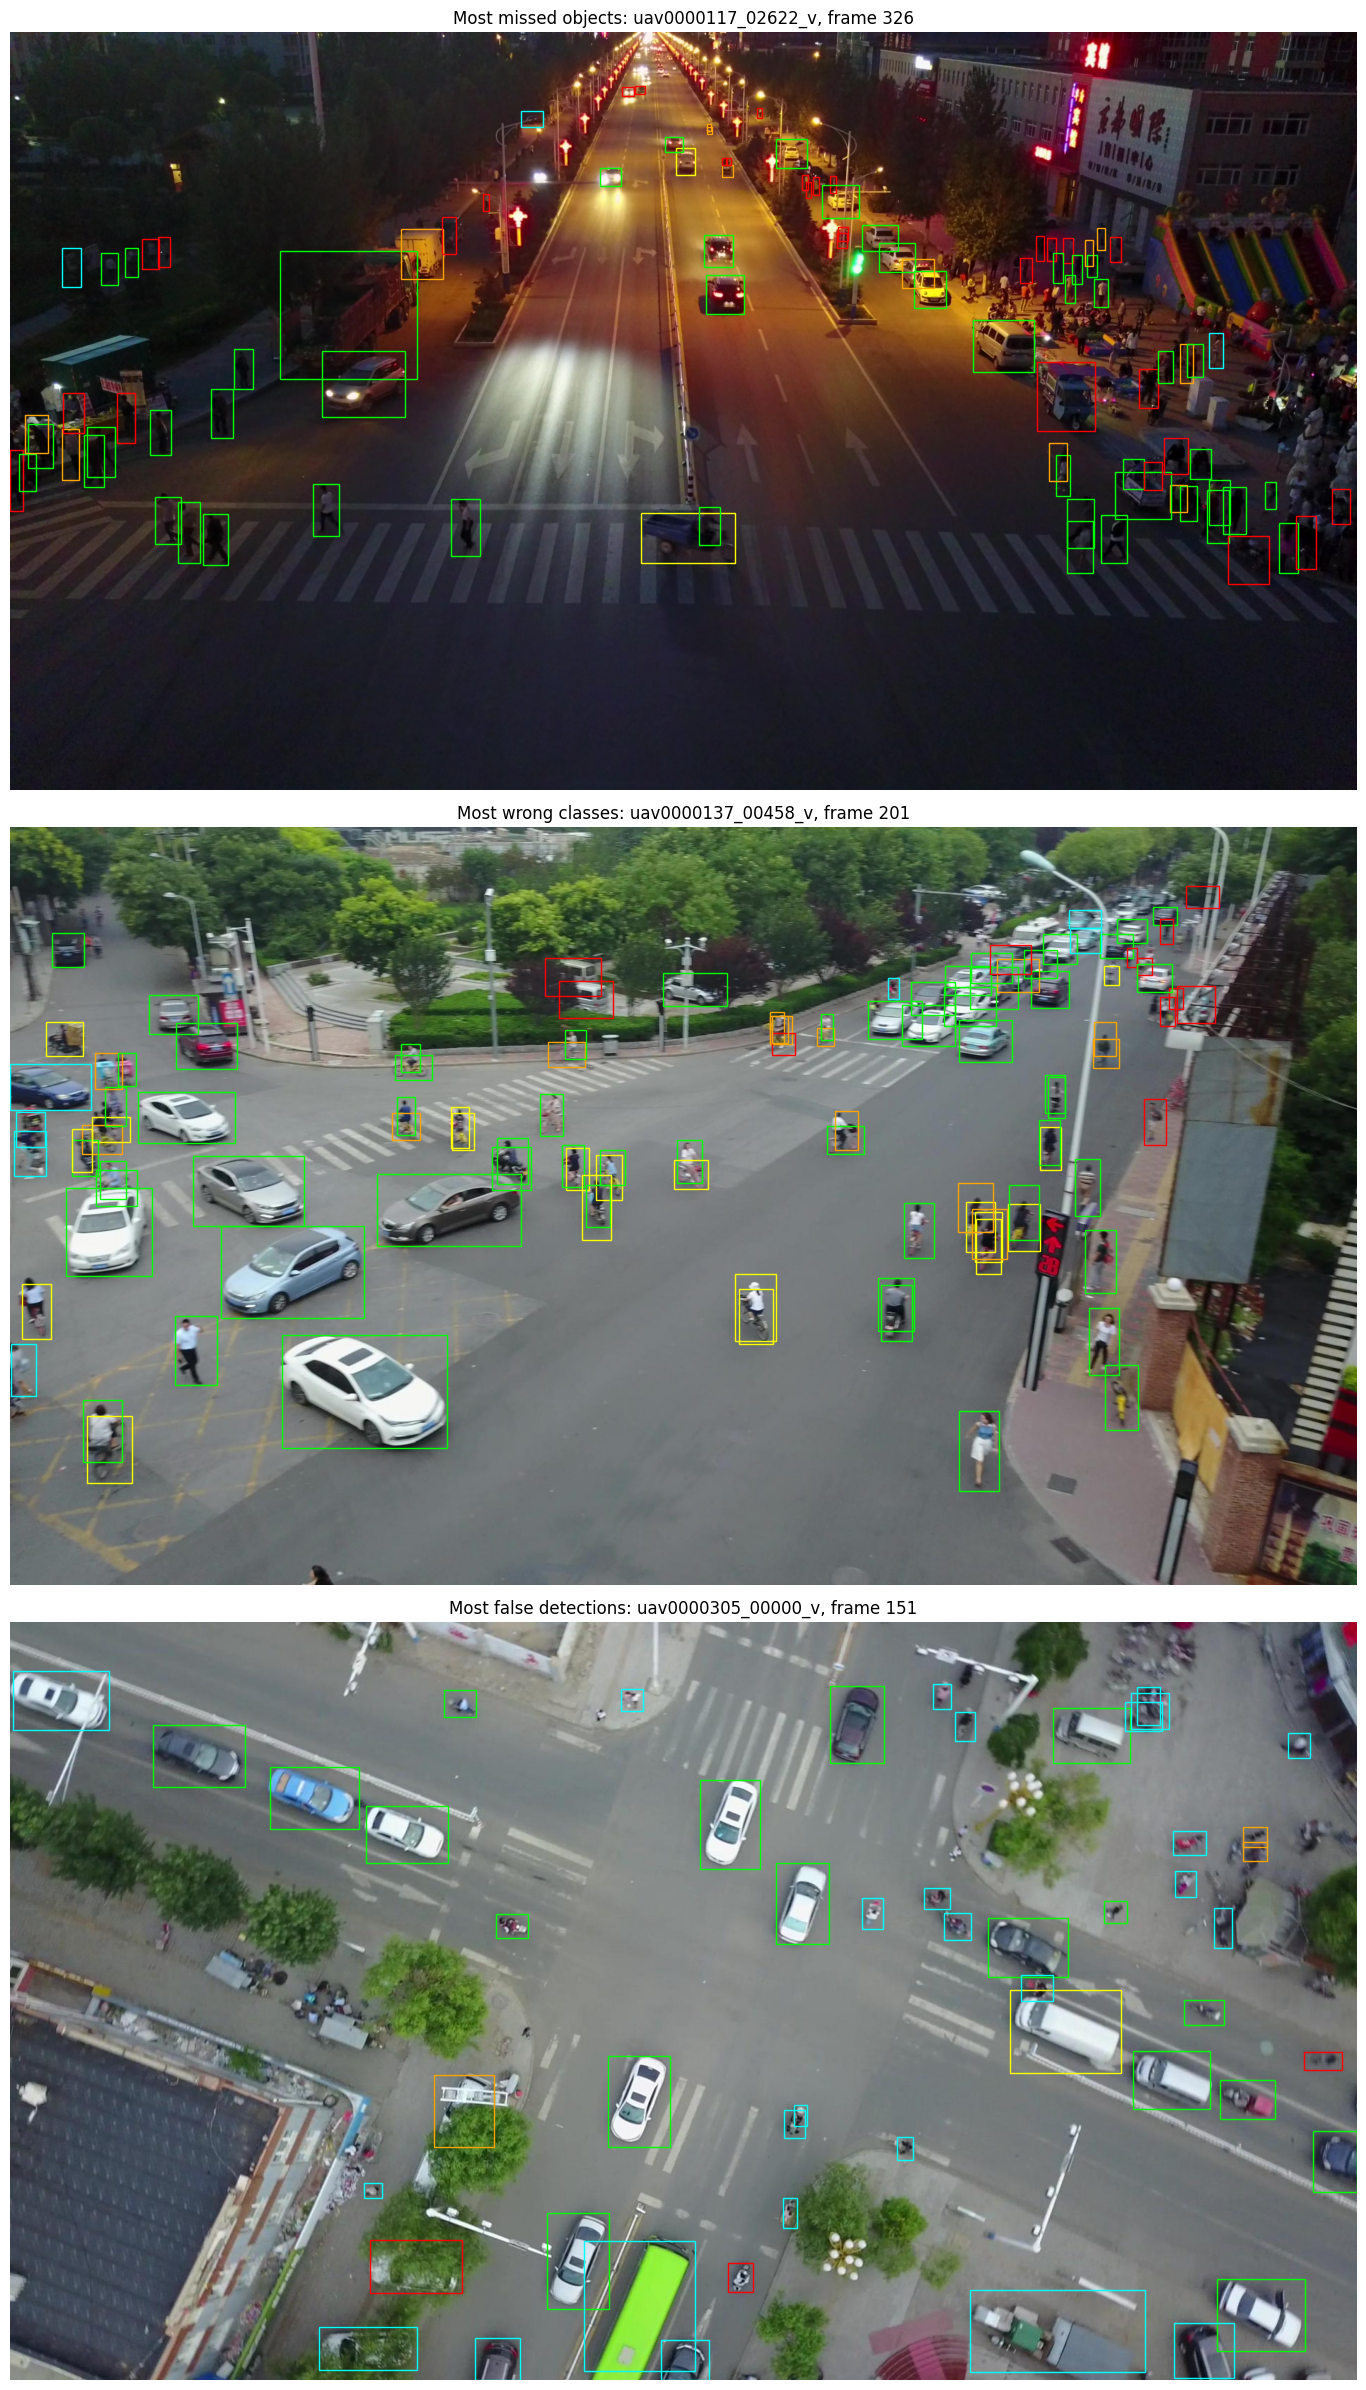

In [ ]:
colours = {"found": "lime", "missed": "red", "wrong class": "yellow", "poor box": "orange"}

picks = {
    "Most missed objects": max(frames, key=lambda k: frames[k][1].count("missed")),
    "Most wrong classes": max(frames, key=lambda k: frames[k][1].count("wrong class")),
    "Most false detections": max(frames, key=lambda k: len(frames[k][2])),
}

fig, axes = plt.subplots(3, 1, figsize=(14, 24))
for ax, (title, image_id) in zip(axes, picks.items()):
    row = val_rows.loc[image_id]
    gt_boxes, status, extra = frames[image_id]
    ax.imshow(Image.open(DATA / "val" / "images" / row["video"] / f'{Path(row["file_name"]).stem}.jpg'))
    for (x1, y1, x2, y2), result in zip(gt_boxes.tolist(), status):
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=colours[result], linewidth=1))
    for x1, y1, x2, y2 in extra.tolist():
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="cyan", linewidth=1))
    ax.set_title(f'{title}: {row["video"]}, frame {row["frame_id"]}')
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. One-stage anchor-based: RetinaNet

**Setup.** RetinaNet with ResNet-50 FPN, pretrained on COCO. Same frames, input, epochs, augmentation and evaluation as Faster R-CNN. Learning rate is halved to 0.0025, following the torchvision reference settings. Tuned anchors use the k-means sizes from 2.9.

In [ ]:
from functools import partial
import torchvision.models.detection.retinanet as rn
from torchvision.models.detection import retinanet_resnet50_fpn
from torchvision.models.detection.retinanet import RetinaNetClassificationHead
from torchvision.ops import sigmoid_focal_loss

DEFAULT_SIZES = (32, 64, 128, 256, 512)
TUNED_SIZES = (12, 24, 48, 96, 192)

def build_retina(base_sizes=TUNED_SIZES):
    model = retinanet_resnet50_fpn(
        weights="DEFAULT",
        min_size=(576, 648, 720),
        max_size=INPUT,
        detections_per_img=300,
        score_thresh=0.01,
    )
    # Three scales per FPN level, as in the original RetinaNet
    scales = (1, 2 ** (1 / 3), 2 ** (2 / 3))
    model.anchor_generator = AnchorGenerator(
        sizes=tuple(tuple(round(s * k) for k in scales) for s in base_sizes),
        aspect_ratios=((0.5, 1.0, 2.0),) * 5,
    )
    # New classification head. Labels stay 1-8, so 9 outputs are needed
    num_anchors = model.head.classification_head.num_anchors
    model.head.classification_head = RetinaNetClassificationHead(256, num_anchors, 9)
    return model

# run() uses these two names, so from here on it trains RetinaNet
LR = 0.0025
build_model = build_retina

In [ ]:
retina_default = run("retina_default", base_sizes=DEFAULT_SIZES)
pd.DataFrame(retina_default).set_index("epoch").round(4)

Downloading: "https://download.pytorch.org/models/retinanet_resnet50_fpn_coco-eeacb38b.pth" to /root/.cache/torch/hub/checkpoints/retinanet_resnet50_fpn_coco-eeacb38b.pth


100%|██████████| 130M/130M [00:01<00:00, 122MB/s]


{'mAP': np.float64(0.0632), 'AP50': np.float64(0.123), 'AP_small': np.float64(0.0208), 'fps': 5.3455, 'epoch': 1, 'loss': 1.0358}
{'mAP': np.float64(0.1086), 'AP50': np.float64(0.2164), 'AP_small': np.float64(0.0387), 'fps': 5.3483, 'epoch': 2, 'loss': 0.5894}
{'mAP': np.float64(0.1263), 'AP50': np.float64(0.2494), 'AP_small': np.float64(0.043), 'fps': 5.3029, 'epoch': 3, 'loss': 0.5265}
{'mAP': np.float64(0.133), 'AP50': np.float64(0.2629), 'AP_small': np.float64(0.0466), 'fps': 5.3474, 'epoch': 4, 'loss': 0.4942}
{'mAP': np.float64(0.1352), 'AP50': np.float64(0.2679), 'AP_small': np.float64(0.0511), 'fps': 5.3431, 'epoch': 5, 'loss': 0.477}
{'mAP': np.float64(0.136), 'AP50': np.float64(0.2681), 'AP_small': np.float64(0.0508), 'fps': 5.358, 'epoch': 6, 'loss': 0.4686}


,mAP,AP50,AP_small,fps,loss
epoch,,,,,
1,0.0632,0.1230,0.0208,5.3455,1.0358
2,0.1086,0.2164,0.0387,5.3483,0.5894
3,0.1263,0.2494,0.0430,5.3029,0.5265
4,0.1330,0.2629,0.0466,5.3474,0.4942
5,0.1352,0.2679,0.0511,5.3431,0.4770
6,0.1360,0.2681,0.0508,5.3580,0.4686


In [ ]:
retina_anchors = run("retina_anchors")
pd.DataFrame(retina_anchors).set_index("epoch").round(4)

Downloading: "https://download.pytorch.org/models/retinanet_resnet50_fpn_coco-eeacb38b.pth" to /root/.cache/torch/hub/checkpoints/retinanet_resnet50_fpn_coco-eeacb38b.pth


100%|██████████| 130M/130M [00:00<00:00, 194MB/s]


{'mAP': np.float64(0.0474), 'AP50': np.float64(0.1258), 'AP_small': np.float64(0.0301), 'fps': 5.4431, 'epoch': 1, 'loss': 1.1813}
{'mAP': np.float64(0.0684), 'AP50': np.float64(0.1785), 'AP_small': np.float64(0.0389), 'fps': 5.453, 'epoch': 2, 'loss': 0.7486}
{'mAP': np.float64(0.082), 'AP50': np.float64(0.211), 'AP_small': np.float64(0.044), 'fps': 5.4288, 'epoch': 3, 'loss': 0.6631}
{'mAP': np.float64(0.0945), 'AP50': np.float64(0.2369), 'AP_small': np.float64(0.0453), 'fps': 5.4661, 'epoch': 4, 'loss': 0.6205}
{'mAP': np.float64(0.0956), 'AP50': np.float64(0.2387), 'AP_small': np.float64(0.0482), 'fps': 5.4652, 'epoch': 5, 'loss': 0.5986}
{'mAP': np.float64(0.0975), 'AP50': np.float64(0.2412), 'AP_small': np.float64(0.0481), 'fps': 5.4192, 'epoch': 6, 'loss': 0.588}


,mAP,AP50,AP_small,fps,loss
epoch,,,,,
1,0.0474,0.1258,0.0301,5.4431,1.1813
2,0.0684,0.1785,0.0389,5.4530,0.7486
3,0.0820,0.2110,0.0440,5.4288,0.6631
4,0.0945,0.2369,0.0453,5.4661,0.6205
5,0.0956,0.2387,0.0482,5.4652,0.5986
6,0.0975,0.2412,0.0481,5.4192,0.5880


In [ ]:
original_focal = rn.sigmoid_focal_loss
rn.sigmoid_focal_loss = partial(sigmoid_focal_loss, gamma=1.5)  # default is 2
try:
    retina_focal = run("retina_focal")
finally:
    rn.sigmoid_focal_loss = original_focal

pd.DataFrame(retina_focal).set_index("epoch").round(4)

{'mAP': np.float64(0.0482), 'AP50': np.float64(0.128), 'AP_small': np.float64(0.0332), 'fps': 8.0925, 'epoch': 1, 'loss': 1.3667}
{'mAP': np.float64(0.0729), 'AP50': np.float64(0.1891), 'AP_small': np.float64(0.0432), 'fps': 7.8839, 'epoch': 2, 'loss': 0.8326}
{'mAP': np.float64(0.0907), 'AP50': np.float64(0.2308), 'AP_small': np.float64(0.0453), 'fps': 7.9139, 'epoch': 3, 'loss': 0.7428}
{'mAP': np.float64(0.1012), 'AP50': np.float64(0.2507), 'AP_small': np.float64(0.0456), 'fps': 8.1352, 'epoch': 4, 'loss': 0.6969}
{'mAP': np.float64(0.1), 'AP50': np.float64(0.2466), 'AP_small': np.float64(0.0467), 'fps': 7.9872, 'epoch': 5, 'loss': 0.6715}
{'mAP': np.float64(0.1037), 'AP50': np.float64(0.2546), 'AP_small': np.float64(0.0477), 'fps': 7.949, 'epoch': 6, 'loss': 0.6592}


,mAP,AP50,AP_small,fps,loss
epoch,,,,,
1,0.0482,0.1280,0.0332,8.0925,1.3667
2,0.0729,0.1891,0.0432,7.8839,0.8326
3,0.0907,0.2308,0.0453,7.9139,0.7428
4,0.1012,0.2507,0.0456,8.1352,0.6969
5,0.1000,0.2466,0.0467,7.9872,0.6715
6,0.1037,0.2546,0.0477,7.9490,0.6592


In [ ]:
names = ["frcnn_base", "retina_default", "retina_anchors", "retina_focal"]
best = lambda history: max(history, key=lambda r: r["mAP"])
pd.DataFrame({n: best(load(n)) for n in names}).T.round(4)

,mAP,AP50,AP_small,fps,epoch,loss
frcnn_base,0.2023,0.4271,0.1019,5.7411,6.0,0.7023
retina_default,0.1360,0.2681,0.0508,5.3580,6.0,0.4686
retina_anchors,0.0975,0.2412,0.0481,5.4192,6.0,0.5880
retina_focal,0.1037,0.2546,0.0477,7.9490,6.0,0.6592


In [ ]:
# Predict every test frame with the best model so far (frcnn_base)
class TestFrames(Dataset):
    def __init__(self, df):
        self.df = df.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(DATA / row["file_name"]).convert("RGB")
        return T.functional.to_tensor(img), row["image_id"]

test_df = pd.read_csv(DATA / "test_images.csv")
test_loader = DataLoader(TestFrames(test_df), batch_size=1, num_workers=2, collate_fn=collate)

model = build_frcnn().to(device)
model.load_state_dict(torch.load(CKPT / "frcnn_base.pt", map_location=device))
model.eval()

rows = []
with torch.no_grad():
    for images, ids in test_loader:
        out = model([images[0].to(device)])[0]  # boxes come back in original pixels
        parts = [f"{label - 1} {score:.4f} {x1:.1f} {y1:.1f} {x2 - x1:.1f} {y2 - y1:.1f}"  # labels 1-8 -> 0-7, xyxy -> xywh
                 for (x1, y1, x2, y2), score, label
                 in zip(out["boxes"].tolist(), out["scores"].tolist(), out["labels"].tolist())]
        rows.append({"image_id": ids[0], "PredictionString": " ".join(parts)})

sub = pd.DataFrame(rows)
sub.to_csv(PROJECT / "submission_frcnn_base.csv", index=False)
print("Rows:", len(sub), "| detections per frame:", sub["PredictionString"].str.split().str.len().div(6).describe().round(1).to_dict())
sub.head()

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:01<00:00, 103MB/s]


Rows: 3811 | detections per frame: {'count': 3811.0, 'mean': 233.0, 'std': 76.2, 'min': 19.0, '25%': 194.0, '50%': 255.0, '75%': 300.0, 'max': 300.0}


,image_id,PredictionString
0,clip_001_0000001,0 0.9985 773.7 887.2 69.3 163.7 0 0.9959 630.0...
1,clip_001_0000002,0 0.9979 771.7 890.7 70.9 167.4 0 0.9958 719.3...
2,clip_001_0000003,0 0.9958 772.5 894.1 64.5 175.7 0 0.9935 713.1...
3,clip_001_0000004,0 0.9943 1726.4 805.2 56.9 150.9 0 0.9940 1673...
4,clip_001_0000005,0 0.9952 1662.5 804.9 54.9 155.9 0 0.9950 727....


In [ ]:
!kaggle competitions submit -c multiple-object-video-detection-hw-2-ucu-ai-2026 -f "{PROJECT}/submission_frcnn_base.csv" -m "Faster R-CNN baseline"

100% 26.3M/26.3M [00:01<00:00, 19.8MB/s]
Successfully submitted to Multiple Object Video Detection | HW2 | UCU AI 2026

## 5-6. One-stage anchor-free and query-based detectors

Trains one run from `RUNS` per execution, evaluates it with the same COCO protocol as sections 3-4, and writes a
submission file. Set `RUN` below, then run from here downwards: this part does not need the cells above it.

In [ ]:
!pip install -q ultralytics==8.4.208 pycocotools

In [ ]:
import os, subprocess, sys

if "google.colab" in sys.modules and not os.path.exists("/content/data/train"):
    from google.colab import drive, userdata
    drive.mount("/content/drive")
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("kaggle").strip()
    slug = "multiple-object-video-detection-hw-2-ucu-ai-2026"
    subprocess.run(f"kaggle competitions download -c {slug} -p /content && unzip -q -o /content/{slug}.zip -d /content/data",
                   shell=True, check=True)

In [ ]:
import hashlib, json, os, shutil
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageDraw

RUN = os.environ.get("HW2_RUN", "yolo_base")
SMOKE = os.environ.get("HW2_SMOKE") == "1"  # tiny fake-data test on CPU

CLASS_NAMES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]
SEED = 42
STEP, MAX_PER_CLIP = 5, 150  # same frames as the anchor-based models
INPUT = 1280                 # long side of the stored train frames
MEAN_COLOUR = (124, 116, 104)
IMGSZ, EPOCHS, BATCH = (160, 1, 2) if SMOKE else (1280, 6, 4)
CONF, NMS_IOU, MAX_DET = 0.01, 0.5, 300  # same inference limits as the anchor-based models
NWD_WEIGHT, NWD_C = 0.5, 30.6            # C: median object size at input 1280, from the EDA
DEVICE = 0 if torch.cuda.is_available() else "cpu"


def find_data_root():
    if "HW2_DATA" in os.environ:
        return Path(os.environ["HW2_DATA"])
    for base in ("/kaggle/input", "/content/data", "data"):
        for pattern in ("train", "*/train", "*/*/train"):
            hits = sorted(Path(base).glob(f"{pattern}/annotations_coco.json"))
            if hits:
                return hits[0].parent.parent
    raise FileNotFoundError("competition data not found")


DATA = find_data_root()
OUT = Path(os.environ.get("HW2_OUT", "/kaggle/working/hw2" if Path("/kaggle/working").exists()
                          else "/content/drive/MyDrive/hw2_detection_b"))
DS = Path(os.environ.get("HW2_DS", "/tmp/hw2_ds"))  # rebuilt per session, not kept
RUN_DIR = OUT / "runs" / RUN
RUN_DIR.mkdir(parents=True, exist_ok=True)
print("Run:", RUN, "| data:", DATA, "| output:", OUT, "| device:", DEVICE)

### Experiments

In [ ]:
YOLO_NAME, YOLO_P2 = ("yolov8n.pt", "yolov8n-p2.yaml") if SMOKE else ("yolov8m.pt", "yolov8m-p2.yaml")

RUNS = {
    "yolo_base":   {"family": "yolo", "model": YOLO_NAME},
    "yolo_p2":     {"family": "yolo", "model": YOLO_P2, "weights": YOLO_NAME},  # extra stride-4 head
    "yolo_nwd":    {"family": "yolo", "model": YOLO_NAME, "nwd": True},         # NWD blended with CIoU
    "rtdetr_base": {"family": "rtdetr", "model": "rtdetr-l.pt"},
    "rtdetr_q500": {"family": "rtdetr", "model": "q500", "weights": "rtdetr-l.pt"},  # 500 queries instead of 300
    "rtdetr_cost": {"family": "rtdetr", "model": "rtdetr-l.pt", "cost": True},  # more weight on box terms
}
spec = RUNS[RUN]

# Augmentation close to the anchor-based models: flip, mild scale and colour jitter, no mosaic
COMMON = dict(
    epochs=EPOCHS, batch=BATCH, imgsz=IMGSZ, seed=SEED, device=DEVICE, workers=4,
    project=str(OUT / "runs"), name=RUN, exist_ok=True,
    save_period=1, val=False,  # each epoch is evaluated afterwards with COCOeval
    cos_lr=True, lrf=0.01, warmup_epochs=0.3,  # the default 3 warmup epochs are half of this budget
    mosaic=0.0, close_mosaic=0, translate=0.0, scale=0.2, fliplr=0.5, hsv_h=0.0, hsv_s=0.2, hsv_v=0.2,
)
TRAIN_ARGS = {
    "yolo": dict(COMMON, optimizer="SGD", lr0=0.01, nbs=16),  # default nbs=64 gives too few updates at batch 4
    "rtdetr": dict(COMMON, optimizer="AdamW", lr0=1e-4, weight_decay=1e-4, nbs=BATCH),
}[spec["family"]]

### Frames

Same selection as the anchor-based models: every 5th frame, seed 42, up to 150 frames per clip.

In [ ]:
coco_by_split = {s: json.load(open(DATA / s / "annotations_coco.json")) for s in ("train", "val")}


def pick_frames(split):
    df = pd.DataFrame(coco_by_split[split]["images"]).sort_values(["video", "frame_id"])
    return df[df.groupby("video").cumcount() % STEP == 0]


val_df = pick_frames("val")
train_df = pick_frames("train").sample(frac=1, random_state=SEED).groupby("video").head(MAX_PER_CLIP)
print("Train frames:", len(train_df), "| val frames:", len(val_df))
print("Frame hash:", hashlib.md5(",".join(map(str, sorted(train_df["id"]))).encode()).hexdigest()[:12])
if not SMOKE:
    assert (len(train_df), len(val_df)) == (4560, 571), "frames differ from the anchor-based models"

boxes_by_image, ignore_by_image = {}, {}
for a in coco_by_split["train"]["annotations"]:
    if a["iscrowd"]:
        ignore_by_image.setdefault(a["image_id"], set()).add(tuple(a["bbox"]))  # one copy per class in the file
    else:
        boxes_by_image.setdefault(a["image_id"], []).append((*a["bbox"], a["category_id"] - 1))


def frame_path(split, row):
    return DATA / split / "images" / row["video"] / f'{Path(row["file_name"]).stem}.jpg'

### Dataset for Ultralytics

Train frames are resized to long side 1280 and ignored regions are filled, so they are not learned as background.
Val frames stay unchanged.

In [ ]:
def write_train_frame(row):
    stem = f'{row["video"]}_{row["frame_id"]}'
    img = Image.open(frame_path("train", row)).convert("RGB")
    scale = INPUT / max(img.size)
    img = img.resize((round(img.width * scale), round(img.height * scale)))
    draw = ImageDraw.Draw(img)
    for x, y, w, h in ignore_by_image.get(row["id"], ()):
        draw.rectangle([x * scale, y * scale, (x + w) * scale, (y + h) * scale], fill=MEAN_COLOUR)
    img.save(DS / "images/train" / f"{stem}.jpg", quality=95)

    lines = []
    for x, y, w, h, cls in boxes_by_image.get(row["id"], ()):
        x1, y1 = np.clip([x * scale, y * scale], 0, img.size)
        x2, y2 = np.clip([(x + w) * scale, (y + h) * scale], 0, img.size)
        if x2 - x1 >= 1 and y2 - y1 >= 1:
            lines.append(f"{cls} {(x1 + x2) / 2 / img.width:.6f} {(y1 + y2) / 2 / img.height:.6f} "
                         f"{(x2 - x1) / img.width:.6f} {(y2 - y1) / img.height:.6f}")
    (DS / "labels/train" / f"{stem}.txt").write_text("\n".join(lines))


def link_val_frame(row):
    stem = f'{row["video"]}_{row["frame_id"]}'
    src = Path(row["file_name"]).stem
    (DS / "images/val" / f"{stem}.jpg").symlink_to(frame_path("val", row).resolve())
    label = (DATA / "val" / "labels" / row["video"] / f"{src}.txt").resolve()
    (DS / "labels/val" / f"{stem}.txt").symlink_to(label)


if not (DS / "done").exists():
    shutil.rmtree(DS, ignore_errors=True)
    for d in ("images/train", "images/val", "labels/train", "labels/val"):
        (DS / d).mkdir(parents=True)
    with ThreadPoolExecutor(4) as pool:
        list(pool.map(write_train_frame, [r for _, r in train_df.iterrows()]))
    for _, r in val_df.iterrows():
        link_val_frame(r)
    (DS / "data.yaml").write_text(
        f"path: {DS}\ntrain: images/train\nval: images/val\nnc: 8\nnames: {CLASS_NAMES}\n")
    (DS / "done").touch()
print("Train images:", len(list((DS / "images/train").iterdir())))

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, (_, row) in zip(axes, train_df.head(2).iterrows()):
    stem = f'{row["video"]}_{row["frame_id"]}'
    img = Image.open(DS / "images/train" / f"{stem}.jpg")
    ax.imshow(img)
    for line in (DS / "labels/train" / f"{stem}.txt").read_text().splitlines():
        _, cx, cy, w, h = map(float, line.split())
        W, H = img.size
        ax.add_patch(plt.Rectangle(((cx - w / 2) * W, (cy - h / 2) * H), w * W, h * H, fill=False, edgecolor="lime"))
    ax.set_title(stem)
    ax.axis("off")
plt.tight_layout()
plt.savefig(RUN_DIR / "train_labels_check.png", dpi=80)
plt.show()

### Evaluation

Same evaluation as the anchor-based models: ignored regions stay as `iscrowd=1`, `maxDets` is raised to 300.
Ultralytics' own validation does not know about ignored regions, so it is not used for comparisons.

In [ ]:
import contextlib, io

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

gt = dict(coco_by_split["val"])
val_ids = set(val_df["id"])
gt["images"] = [x for x in gt["images"] if x["id"] in val_ids]
gt["annotations"] = [dict(x, area=x["bbox"][2] * x["bbox"][3]) for x in gt["annotations"] if x["image_id"] in val_ids]
with contextlib.redirect_stdout(io.StringIO()):
    coco_gt = COCO()
    coco_gt.dataset = gt
    coco_gt.createIndex()


def predict_image(model, path):
    # RT-DETR outputs are not sorted by score, so ask for all boxes and keep the top MAX_DET here
    r = model.predict(str(path), imgsz=IMGSZ, conf=CONF, iou=NMS_IOU, max_det=1000,
                      device=DEVICE, verbose=False, save=False)[0]
    b = r.boxes
    seconds = sum(r.speed.values()) / 1000
    scores = b.conf.cpu().numpy()
    top = np.argsort(-scores)[:MAX_DET]
    return b.xyxy.cpu().numpy()[top], scores[top], b.cls.cpu().numpy().astype(int)[top], seconds


def evaluate(model):
    results, seconds = [], 0.0
    for _, row in val_df.iterrows():
        xyxy, scores, classes, sec = predict_image(model, frame_path("val", row))
        seconds += sec
        for (x1, y1, x2, y2), s, c in zip(xyxy.tolist(), scores.tolist(), classes.tolist()):
            results.append({"image_id": int(row["id"]), "category_id": c + 1,
                            "bbox": [x1, y1, x2 - x1, y2 - y1], "score": s})
    metrics = {"mAP": 0.0, "AP50": 0.0, "AP_small": 0.0, "AP_medium": 0.0, "AP_large": 0.0,
               "fps": len(val_df) / max(seconds, 1e-9)}
    if results:
        with contextlib.redirect_stdout(io.StringIO()):
            ev = COCOeval(coco_gt, coco_gt.loadRes(results), "bbox")
            ev.params.maxDets = [1, 100, 300]
            ev.evaluate(); ev.accumulate(); ev.summarize()
        metrics.update(mAP=ev.stats[0], AP50=ev.stats[1], AP_small=ev.stats[3], AP_medium=ev.stats[4], AP_large=ev.stats[5])
    return {k: float(v) for k, v in metrics.items()}

### Experiment changes

NWD ([Wang et al.](https://arxiv.org/abs/2110.13389)) is less sensitive than IoU to small shifts of tiny boxes.
The matching cost run raises the box terms, because L1 on normalised coordinates is very small for tiny objects.

In [ ]:
import ultralytics.utils.loss as yolo_loss
from ultralytics import RTDETR, YOLO
from ultralytics.models.utils import loss as detr_loss
from ultralytics.models.utils.ops import HungarianMatcher


def apply_nwd():
    original_iou, original_forward = yolo_loss.bbox_iou, yolo_loss.BboxLoss.forward
    current = {}

    def forward(self, pred_dist, pred_bboxes, anchor_points, target_bboxes, target_scores,
                target_scores_sum, fg_mask, imgsz, stride):
        # Boxes arrive in stride units, NWD needs pixels
        current["stride"] = stride[fg_mask.nonzero(as_tuple=True)[1]]
        return original_forward(self, pred_dist, pred_bboxes, anchor_points, target_bboxes, target_scores,
                                target_scores_sum, fg_mask, imgsz, stride)

    def blended(box1, box2, **kwargs):
        iou = original_iou(box1, box2, **kwargs)
        s = current["stride"]
        c1, c2 = (box1[:, :2] + box1[:, 2:]) / 2 * s, (box2[:, :2] + box2[:, 2:]) / 2 * s
        wh1, wh2 = (box1[:, 2:] - box1[:, :2]) * s, (box2[:, 2:] - box2[:, :2]) * s
        dist2 = ((c1 - c2) ** 2).sum(1, keepdim=True) + ((wh1 - wh2) ** 2).sum(1, keepdim=True) / 4
        nwd = torch.exp(-torch.sqrt(dist2 + 1e-7) / NWD_C)
        return (1 - NWD_WEIGHT) * iou + NWD_WEIGHT * nwd

    yolo_loss.BboxLoss.forward = forward
    yolo_loss.bbox_iou = blended


def apply_cost():
    original_init = detr_loss.DETRLoss.__init__

    def init(self, *args, **kwargs):
        original_init(self, *args, **kwargs)
        self.matcher = HungarianMatcher(cost_gain={"class": 2, "bbox": 8, "giou": 4})
        self.loss_gain.update(bbox=8, giou=4)

    detr_loss.DETRLoss.__init__ = init


def q500_config():
    import ultralytics
    text = (Path(ultralytics.__file__).parent / "cfg/models/rt-detr/rtdetr-l.yaml").read_text()
    assert "RTDETRDecoder, [nc]" in text
    path = RUN_DIR / "rtdetr-l-q500.yaml"
    path.write_text(text.replace("RTDETRDecoder, [nc]", "RTDETRDecoder, [nc, 256, 500]"))
    return str(path)


Family = RTDETR if spec["family"] == "rtdetr" else YOLO
if spec.get("nwd"):
    apply_nwd()
if spec.get("cost"):
    apply_cost()

### Training

In [ ]:
last, done = RUN_DIR / "weights/last.pt", RUN_DIR / "train_done"
if done.exists():
    print("Already trained")
elif last.exists():
    Family(str(last)).train(resume=True)
    done.touch()
else:
    model = Family(q500_config() if spec["model"] == "q500" else spec["model"])
    if "weights" in spec:
        model.load(spec["weights"])
    model.train(data=str(DS / "data.yaml"), **TRAIN_ARGS)
    done.touch()
torch.cuda.empty_cache()

### Validation results per epoch

In [ ]:
history_file, best_file = RUN_DIR / "history.json", RUN_DIR / "best_coco.pt"
if history_file.exists():
    history = json.loads(history_file.read_text())
else:
    checkpoints = sorted((RUN_DIR / "weights").glob("epoch*.pt"), key=lambda p: int(p.stem[5:]))
    assert len(checkpoints) == EPOCHS, f"expected {EPOCHS} checkpoints, found {len(checkpoints)}"
    history = []
    for path in checkpoints:
        metrics = evaluate(Family(str(path)))
        metrics["epoch"] = int(path.stem[5:]) + 1
        history.append(metrics)
        print({k: round(v, 4) for k, v in metrics.items()})
        if metrics["mAP"] >= max(h["mAP"] for h in history):
            shutil.copy(path, best_file)
    history_file.write_text(json.dumps(history, indent=1))
    for path in checkpoints:  # only the best epoch is kept, to save space
        path.unlink()

best = max(history, key=lambda h: h["mAP"])
(RUN_DIR / "result.json").write_text(json.dumps({"run": RUN, **best}, indent=1))
print("Best:", {k: round(v, 4) for k, v in best.items()})
pd.DataFrame(history).set_index("epoch").round(4)

In [ ]:
final_model = Family(str(best_file))
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, (_, row) in zip(axes, val_df.sample(2, random_state=SEED).iterrows()):
    path = frame_path("val", row)
    xyxy, scores, classes, _ = predict_image(final_model, path)
    ax.imshow(Image.open(path))
    for (x1, y1, x2, y2), s in zip(xyxy.tolist(), scores.tolist()):
        if s >= 0.3:
            ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="cyan"))
    ax.set_title(f'{row["video"]} frame {row["frame_id"]}')
    ax.axis("off")
plt.tight_layout()
plt.savefig(RUN_DIR / "val_predictions.png", dpi=80)
plt.show()

### Submission

Boxes are in original pixels as `class score x y width height`, with 0-based classes.

In [ ]:
test_df = pd.read_csv(DATA / "test_images.csv")
rows = []
for _, row in test_df.iterrows():
    xyxy, scores, classes, _ = predict_image(final_model, DATA / row["file_name"])
    parts = [f"{c} {s:.4f} {x1:.1f} {y1:.1f} {x2 - x1:.1f} {y2 - y1:.1f}"
             for (x1, y1, x2, y2), s, c in zip(xyxy.tolist(), scores.tolist(), classes.tolist())]
    rows.append({"image_id": row["image_id"], "PredictionString": " ".join(parts)})
sub = pd.DataFrame(rows)

counts = sub["PredictionString"].str.split().str.len().div(6)
assert sub["image_id"].tolist() == test_df["image_id"].tolist() and counts.max() <= 500
assert (counts % 1 == 0).all()
sub.to_csv(RUN_DIR / f"submission_{RUN}.csv", index=False)
print("Rows:", len(sub), "| detections per frame:", counts.describe().round(1).to_dict())

### All finished runs

In [ ]:
summary = [json.loads(p.read_text()) for p in sorted((OUT / "runs").glob("*/result.json"))]
display(pd.DataFrame(summary).set_index("run").round(4))

In [ ]:
# Stops "run cell and below" here after training. Set to True to run the comparisons in sections 5-6.
RUN_ANALYSIS = False
assert RUN_ANALYSIS, "Training finished. Comparisons are switched off: set RUN_ANALYSIS = True to run sections 5-6"

### 5-6.10 Comparison code
Caches predictions, reads saved results, and scores the saved anchor-based checkpoints again for results by object size. No training. A checkpoint is skipped if it isn't found at `ANCHOR_CKPT`.

**To run sections 5 and 6:** restart the session, keep `RUN = "yolo_base"`, and run the setup cells at the top of 5-6 plus 5-6.1, 5-6.2, 5-6.4 and 5-6.5. Then set `RUN_ANALYSIS = True` in the cell above and run from there down.

In [ ]:
import pickle, time


PREDS = OUT / "preds"
REPORT = OUT / "report"
PREDS.mkdir(exist_ok=True)
REPORT.mkdir(exist_ok=True)
test_frames = pd.read_csv(DATA / "test_images.csv")
ANCHOR_CKPT = Path(os.environ.get("HW2_ANCHOR_CKPT", OUT.parent / "hw2_detection" / "checkpoints"))


def frames_of(split):
    if split == "val":
        return [(int(r["id"]), frame_path("val", r), r["width"], r["height"]) for _, r in val_df.iterrows()]
    return [(r["image_id"], DATA / r["file_name"], r["width"], r["height"]) for _, r in test_frames.iterrows()]


def cached(name, split, predict_frame):
    """Predict all frames once and keep them as {key: (xyxy, scores, classes)} plus frames per second."""
    path = PREDS / f"{name}_{split}.pkl"
    if path.exists():
        return pickle.loads(path.read_bytes())
    preds, start = {}, time.perf_counter()
    frames = frames_of(split)
    for key, image, w, h in frames:
        preds[key] = predict_frame(image, w, h)
    out = (preds, len(frames) / (time.perf_counter() - start))
    path.write_bytes(pickle.dumps(out))
    return out


finished = [r for r in RUNS if (OUT / "runs" / r / "result.json").exists()]


def run_rows(family):
    """Saved validation results of all finished runs of one model family."""
    rows = []
    for r in finished:
        if RUNS[r]["family"] == family:
            saved = json.loads((OUT / "runs" / r / "result.json").read_text())
            rows.append({"model": r, "family": family,
                         **{k: saved[k] for k in ("mAP", "AP50", "AP_small", "AP_medium", "AP_large", "fps")}})
    return rows

In [ ]:
def score(preds):
    results = [{"image_id": key, "category_id": int(c) + 1, "bbox": [x1, y1, x2 - x1, y2 - y1], "score": float(s)}
               for key, (xyxy, scores, classes) in preds.items()
               for (x1, y1, x2, y2), s, c in zip(xyxy.tolist(), scores, classes)]
    names = ["mAP", "AP50", "AP_small", "AP_medium", "AP_large"]
    if not results:
        return dict.fromkeys(names, 0.0)
    with contextlib.redirect_stdout(io.StringIO()):
        ev = COCOeval(coco_gt, coco_gt.loadRes(results), "bbox")
        ev.params.maxDets = [1, 100, 300]
        ev.evaluate(); ev.accumulate(); ev.summarize()
    return {n: float(ev.stats[i]) for n, i in zip(names, (0, 1, 3, 4, 5))}

In [ ]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn, retinanet_resnet50_fpn
from torchvision.models.detection.anchor_utils import AnchorGenerator
from torchvision.transforms.functional import to_tensor

SIZES_TUNED, SIZES_DEFAULT = (12, 24, 48, 96, 192), (32, 64, 128, 256, 512)


def build_anchor_model(name):
    shared = dict(weights=None, weights_backbone=None, num_classes=9, min_size=(576, 648, 720), max_size=INPUT)
    if name.startswith("frcnn"):
        model = fasterrcnn_resnet50_fpn(box_detections_per_img=MAX_DET, box_score_thresh=CONF, **shared)
        model.rpn.anchor_generator = AnchorGenerator(tuple((s,) for s in SIZES_TUNED), ((0.5, 1.0, 2.0),) * 5)
    else:
        model = retinanet_resnet50_fpn(detections_per_img=MAX_DET, score_thresh=CONF, **shared)
        base = SIZES_DEFAULT if name == "retina_default" else SIZES_TUNED
        scales = (1, 2 ** (1 / 3), 2 ** (2 / 3))
        model.anchor_generator = AnchorGenerator(tuple(tuple(round(s * k) for k in scales) for s in base),
                                                 ((0.5, 1.0, 2.0),) * 5)
    model.load_state_dict(torch.load(ANCHOR_CKPT / f"{name}.pt", map_location="cpu"))
    return model.to(DEVICE).eval()


@torch.no_grad()
def anchor_preds(name):
    model = build_anchor_model(name)

    def predict(image, w, h):
        out = model([to_tensor(Image.open(image).convert("RGB")).to(DEVICE)])[0]
        return out["boxes"].cpu().numpy(), out["scores"].cpu().numpy(), out["labels"].cpu().numpy().astype(int) - 1

    return cached(name, "val", predict)


anchor_rows = []
for name in ("frcnn_base", "frcnn_giou", "retina_default", "retina_anchors", "retina_focal"):
    if (ANCHOR_CKPT / f"{name}.pt").exists():
        preds, fps = anchor_preds(name)
        anchor_rows.append({"model": name, "family": "anchor-based", **score(preds), "fps": fps})
    else:
        print("Skipped, no checkpoint:", name)

## 5. One-stage Anchor-free: YOLOv8

**Core idea.** No preset anchor boxes: each location on the feature map predicts its class and its distance to the object's edges. Overlapping boxes are removed afterwards with NMS.

| Run | What changes | Why try it |
|---|---|---|
| `yolo_base` | Nothing: YOLOv8m pretrained on COCO | Reference point |
| `yolo_p2` | Extra high-resolution head (stride 4) | Tiny objects can disappear at coarser levels |
| `yolo_nwd` | Box loss blends NWD with CIoU | IoU drops sharply when a tiny box shifts by a few pixels |

Trained with the code in 5-6.

### 5.1 Comparison with anchor-based models
Results by object size.

In [ ]:
# Anchor-free runs next to the anchor-based models, broken down by object size
section5 = pd.DataFrame(run_rows("yolo") + anchor_rows).sort_values("mAP", ascending=False).reset_index(drop=True)
section5.to_csv(REPORT / "anchor_free_vs_anchor_based.csv", index=False)
section5.round(4)

## 6. Query-based: RT-DETR

**Core idea.** A transformer uses a fixed set of object queries. In training, bipartite matching gives each true object exactly one query, so duplicates are penalised and NMS is not needed.

| Run | What changes | Why try it |
|---|---|---|
| `rtdetr_base` | Nothing: RT-DETR-L pretrained on COCO, 300 queries | Reference point |
| `rtdetr_q500` | 500 queries | Scenes can hold up to 180 objects |
| `rtdetr_cost` | Higher box weights in matching and in the loss | L1 on normalised coordinates is very small for tiny objects |

Trained with the code in 5-6, on the same budget as the CNN detectors.

### 6.1 Comparison with CNN detectors
Results by object size.

In [ ]:
# Query-based runs next to the best CNN detectors
section6 = pd.DataFrame(run_rows("rtdetr") + run_rows("yolo") + anchor_rows).sort_values("mAP", ascending=False).reset_index(drop=True)
section6.to_csv(REPORT / "query_based_vs_cnn.csv", index=False)
section6.round(4)

### 6.2 mAP during training
RT-DETR against CNN detectors over the same 6-epoch budget.

In [ ]:
# Faster R-CNN values come from the history printed in section 3
CNN_HISTORY = {"Faster R-CNN": [0.1789, 0.1868, 0.1928, 0.1937, 0.2009, 0.2023]}
curves = dict(CNN_HISTORY)
for label, run in (("YOLOv8m", "yolo_base"), ("RT-DETR", "rtdetr_base")):
    path = OUT / "runs" / run / "history.json"
    if path.exists():
        curves[label] = [h["mAP"] for h in json.loads(path.read_text())]

SERIES_COLOURS = {"Faster R-CNN": "#2a78d6", "YOLOv8m": "#eb6834", "RT-DETR": "#1baf7a"}  # fixed per model
fig, ax = plt.subplots(figsize=(8, 4.5), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
for label, values in curves.items():
    epochs = range(1, len(values) + 1)
    ax.plot(epochs, values, color=SERIES_COLOURS[label], linewidth=2, marker="o", markersize=6, label=label)
    ax.annotate(f"{label} {values[-1]:.3f}", (len(values), values[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", color="#333333")
ax.set(xlabel="Epoch", ylabel="Validation mAP", title="Validation mAP over the same 6-epoch budget")
ax.set_xticks(range(1, 7))
ax.set_xlim(0.8, 7.6)
ax.set_ylim(bottom=0)
ax.grid(axis="y", color="#e5e5e2", linewidth=1)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig(REPORT / "map_over_training.png", dpi=120)
plt.show()